#DBSCAN CLUSTERING ASSIGNMENT - PENGUINS DATASET

# STEP 1: IMPORT NECESSARY LIBRARIES

What are we doing here?
-----------------------
We're importing Python libraries that we need for data analysis, visualization,
and machine learning. Think of libraries as toolkits with ready-made functions.

Why each library?
- pandas: For loading and manipulating data (like Excel in Python)
- numpy: For numerical calculations and array operations
- matplotlib & seaborn: For creating beautiful visualizations
- sklearn: Contains all machine learning algorithms including DBSCAN

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.neighbors import NearestNeighbors
import warnings
warnings.filterwarnings('ignore')

# Set style for better-looking plots
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("✓ All libraries imported successfully!")
print("=" * 80)

✓ All libraries imported successfully!


# STEP 2: LOAD AND EXPLORE THE DATA

What are we doing?
-------------------
Loading the dataset and examining its basic characteristics. This helps us
understand what we're working with before applying the algorithm.

Think of this like:
- Reading a book's table of contents before reading it
- Checking a puzzle box to see how many pieces there are before starting

In [ ]:
#Load the Dataset

df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/DBScan_Clustering Penguins Species/penguins.csv')

In [ ]:
df.shape

(344, 5)

In [ ]:
df.dtypes

,0
culmen_length_mm,float64
culmen_depth_mm,float64
flipper_length_mm,float64
body_mass_g,float64
sex,object


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   342 non-null    float64
 1   culmen_depth_mm    342 non-null    float64
 2   flipper_length_mm  342 non-null    float64
 3   body_mass_g        342 non-null    float64
 4   sex                335 non-null    object 
dtypes: float64(4), object(1)
memory usage: 13.6+ KB


In [ ]:
df.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,214.014620,4201.754386
std,5.459584,1.974793,260.558057,801.954536
min,32.100000,13.100000,-132.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.750000,4750.000000
max,59.600000,21.500000,5000.000000,6300.000000


In [ ]:
df.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


In [ ]:
df.isnull().sum()

,0
culmen_length_mm,2
culmen_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,9


# STEP 3: DATA CLEANING AND PREPROCESSING

What are we doing?
-------------------
Cleaning the data by:
1. Removing rows with missing values
2. Removing outliers (impossible values)
3. Selecting only numerical features for clustering

Why is this important?
- DBSCAN works with numbers, so we need numerical data
- Missing data can mess up our calculations
- Outliers (like flipper_length of 5000 mm!) are data errors that would distort results

In [ ]:
# Create a working copy of the dataframe
df_clean = df.copy()

In [ ]:
# Remove rows with missing values (NA)
print(f"Original dataset: {len(df_clean)} rows")
df_clean = df_clean.dropna()
print(f"After removing missing values: {len(df_clean)} rows")
print(f"Removed {len(df) - len(df_clean)} rows with missing data")

Original dataset: 344 rows
After removing missing values: 335 rows
Removed 9 rows with missing data


In [ ]:
# Remove obvious outliers (impossible measurements)
# Flipper length should be between 150-250mm
# Body mass should be between 2500-6500g
df_clean = df_clean[
    (df_clean['flipper_length_mm'] > 150) &
    (df_clean['flipper_length_mm'] < 250) &
    (df_clean['body_mass_g'] > 2500) &
    (df_clean['body_mass_g'] < 6500)
]
print(f"After removing outliers: {len(df_clean)} rows")

# Select only numerical features for clustering
# We ignore 'sex' because it's categorical (not a number)
features_for_clustering = ['culmen_length_mm', 'culmen_depth_mm',
                            'flipper_length_mm', 'body_mass_g']

X = df_clean[features_for_clustering].copy()

print(f"\n✓ Data cleaned successfully!")
print(f"Features selected for clustering: {features_for_clustering}")
print(f"\nBasic Statistics of Cleaned Data:")
print(X.describe().round(2))

After removing outliers: 333 rows

✓ Data cleaned successfully!
Features selected for clustering: ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']

Basic Statistics of Cleaned Data:
       culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g
count            333.00           333.00             333.00       333.00
mean              44.02            17.15             201.02      4208.48
std                5.44             1.96              14.04       805.98
min               32.10            13.10             172.00      2700.00
25%               39.50            15.60             190.00      3550.00
50%               44.50            17.30             197.00      4050.00
75%               48.60            18.70             213.00      4800.00
max               59.60            21.50             231.00      6300.00


# STEP 4: DATA EXPLORATION & VISUALIZATION

What are we doing?
-------------------
Creating visualizations to understand the data before clustering.
This helps us make better decisions about DBSCAN parameters.

Why visualizations?
- Humans understand patterns in images better than numbers
- We can spot if data is clustered or spread out
- We can see if there are outliers

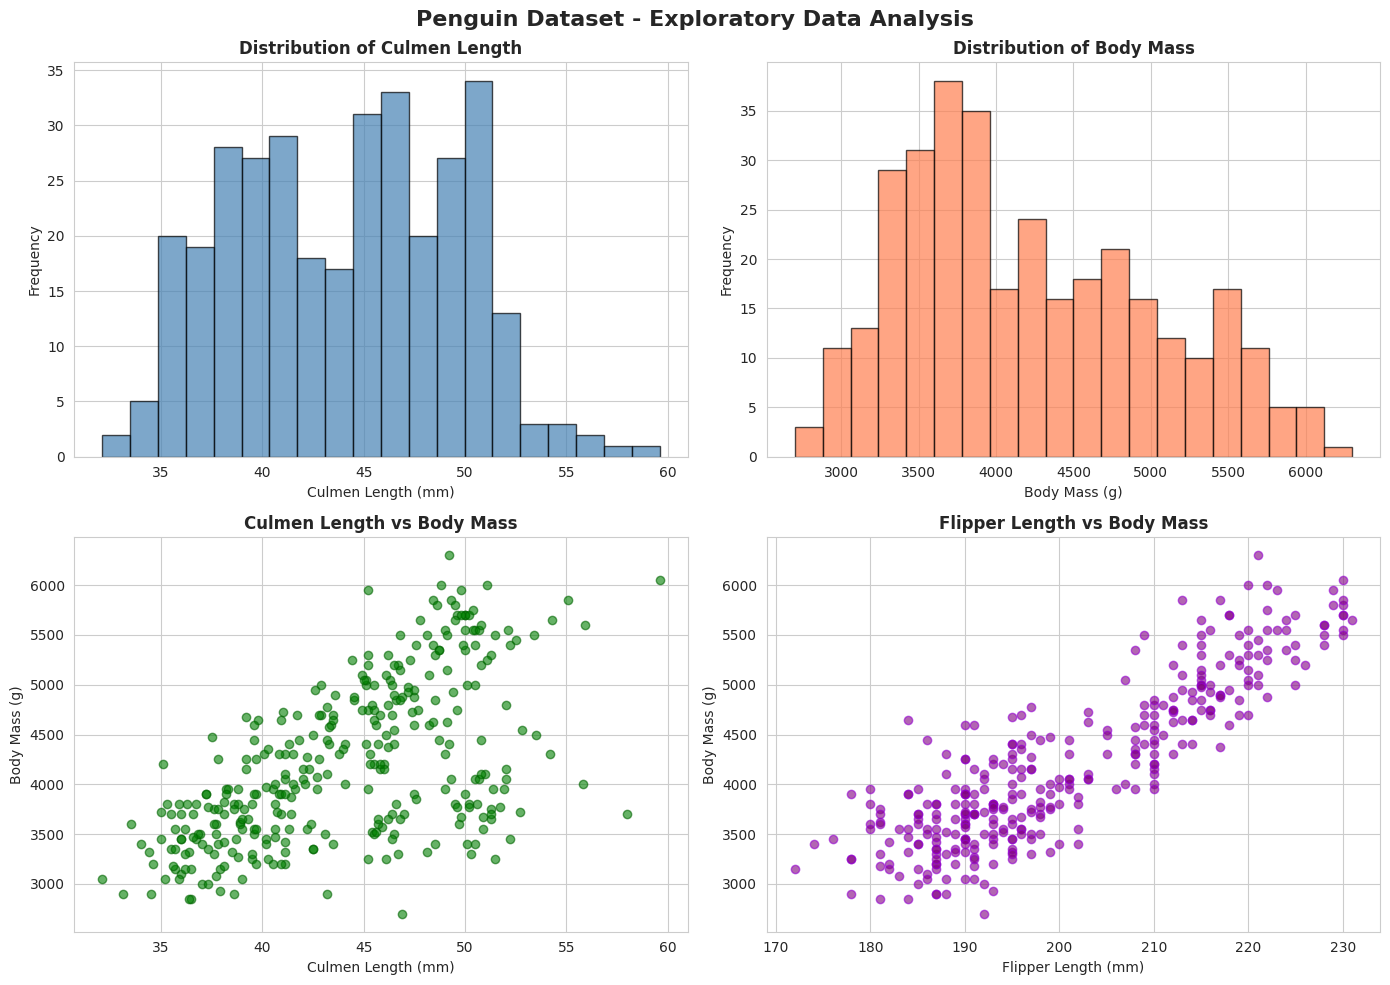

In [ ]:
# Create a figure with multiple subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Penguin Dataset - Exploratory Data Analysis', fontsize=16, fontweight='bold')

# 1. Distribution of Culmen Length
axes[0, 0].hist(X['culmen_length_mm'], bins=20, color='steelblue', edgecolor='black', alpha=0.7)
axes[0, 0].set_title('Distribution of Culmen Length', fontweight='bold')
axes[0, 0].set_xlabel('Culmen Length (mm)')
axes[0, 0].set_ylabel('Frequency')

# 2. Distribution of Body Mass
axes[0, 1].hist(X['body_mass_g'], bins=20, color='coral', edgecolor='black', alpha=0.7)
axes[0, 1].set_title('Distribution of Body Mass', fontweight='bold')
axes[0, 1].set_xlabel('Body Mass (g)')
axes[0, 1].set_ylabel('Frequency')

# 3. Scatter plot: Culmen Length vs Body Mass
axes[1, 0].scatter(X['culmen_length_mm'], X['body_mass_g'],
                   color='green', alpha=0.6, edgecolors='darkgreen')
axes[1, 0].set_title('Culmen Length vs Body Mass', fontweight='bold')
axes[1, 0].set_xlabel('Culmen Length (mm)')
axes[1, 0].set_ylabel('Body Mass (g)')

# 4. Scatter plot: Flipper Length vs Body Mass
axes[1, 1].scatter(X['flipper_length_mm'], X['body_mass_g'],
                   color='purple', alpha=0.6, edgecolors='darkviolet')
axes[1, 1].set_title('Flipper Length vs Body Mass', fontweight='bold')
axes[1, 1].set_xlabel('Flipper Length (mm)')
axes[1, 1].set_ylabel('Body Mass (g)')

plt.tight_layout()
plt.show()


📊 Correlation Matrix (how features relate to each other):
                   culmen_length_mm  culmen_depth_mm  flipper_length_mm  \
culmen_length_mm              1.000           -0.221              0.654   
culmen_depth_mm              -0.221            1.000             -0.581   
flipper_length_mm             0.654           -0.581              1.000   
body_mass_g                   0.593           -0.477              0.873   

                   body_mass_g  
culmen_length_mm         0.593  
culmen_depth_mm         -0.477  
flipper_length_mm        0.873  
body_mass_g              1.000  


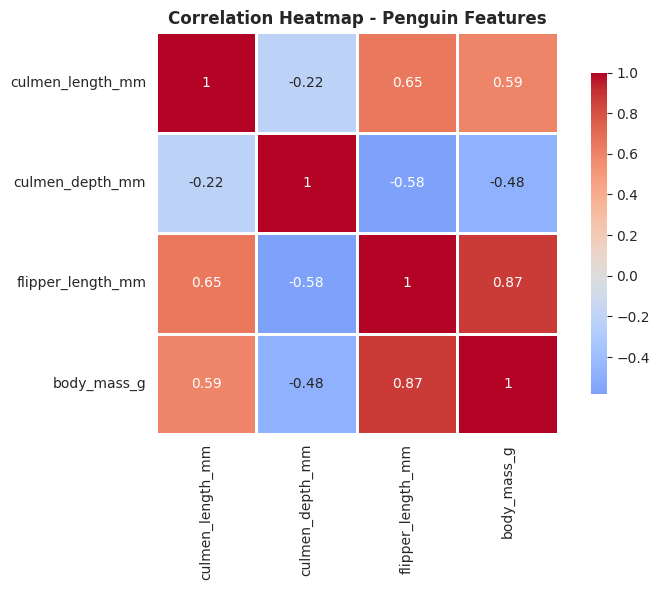

In [ ]:
# Create a correlation heatmap
print("\n📊 Correlation Matrix (how features relate to each other):")
correlation_matrix = X.corr()
print(correlation_matrix.round(3))

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
            square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Correlation Heatmap - Penguin Features', fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()

# STEP 5: FEATURE STANDARDIZATION

What are we doing?
-------------------
Scaling all features to have the same range (0-1). This is important because:

Example of why this matters:
- Body Mass ranges from ~2700 to ~6300 (range of ~3600)
- Culmen Length ranges from ~32 to ~46 (range of ~14)

Without scaling, Body Mass would dominate the distance calculations
because its values are so much larger. Scaling makes all features
equally important in DBSCAN's distance calculations.

How it works:
Standardization formula: (value - mean) / standard_deviation
This transforms each feature to have mean=0 and standard_deviation=1

In [ ]:
# Initialize the StandardScaler
scaler = StandardScaler()

In [ ]:
# Fit and transform the data
X_scaled = scaler.fit_transform(X)

In [ ]:
X_scaled

array([[-0.90552018,  0.79312591, -1.42812496, -0.56970896],
       [-0.83193838,  0.12850298, -1.07152207, -0.50757924],
       [-0.68477478,  0.43525202, -0.42963687, -1.1910061 ],
       ...,
       [ 1.17316569, -0.74061931,  1.49601872,  1.91547962],
       [ 0.21660228, -1.20074288,  0.78281295,  1.23205276],
       [ 1.08118844, -0.53611995,  0.85413352,  1.48057162]])

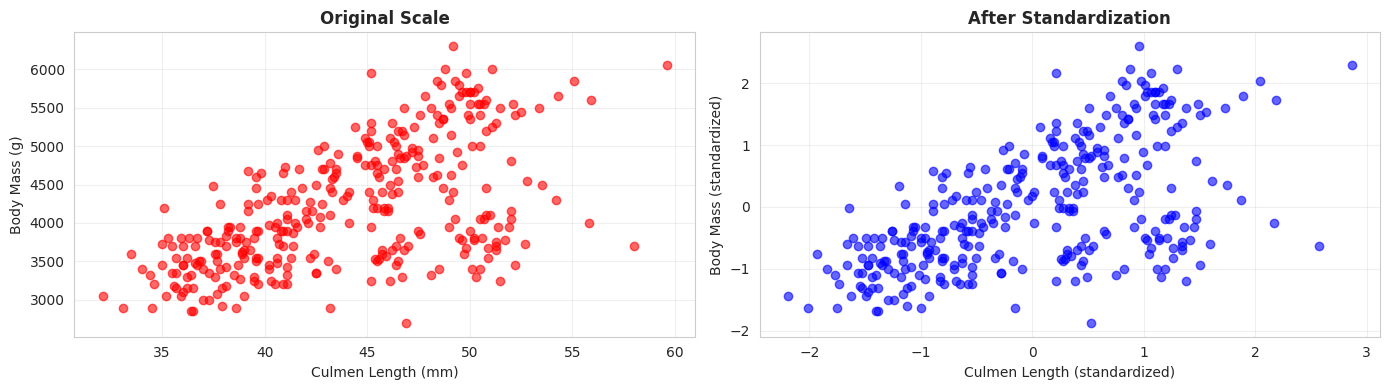

In [ ]:
# Visualize the scaling effect
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Original scale
axes[0].scatter(X['culmen_length_mm'], X['body_mass_g'], alpha=0.6, color='red')
axes[0].set_title('Original Scale', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Culmen Length (mm)')
axes[0].set_ylabel('Body Mass (g)')
axes[0].grid(True, alpha=0.3)

# Scaled
axes[1].scatter(X_scaled[:, 0], X_scaled[:, 3], alpha=0.6, color='blue')
axes[1].set_title('After Standardization', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Culmen Length (standardized)')
axes[1].set_ylabel('Body Mass (standardized)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# STEP 6: FINDING OPTIMAL EPSILON (ε) VALUE

What is Epsilon (ε)?
--------------------
Epsilon is the maximum distance within which DBSCAN looks for neighbors.
Think of it as a "bubble" around each point - if another point falls
within this bubble, they could belong to the same cluster.

Why is finding ε important?
- ε too small: All points become noise (no clusters formed)
- ε too large: All points merge into one giant cluster
- ε just right: We get meaningful clusters

How do we find the right ε?
We use the K-distance graph:
1. Calculate the distance to the k-th nearest neighbor for each point
2. Sort these distances in descending order
3. Plot them - the "elbow" point suggests a good ε value

In [ ]:
# Calculate k-distance for each point
# We use k=4 (minimum samples parameter, explained later)
k = 4
neighbors = NearestNeighbors(n_neighbors=k)
neighbors_fit = neighbors.fit(X_scaled)

# Get distances to the k-th nearest neighbor
distances, indices = neighbors_fit.kneighbors(X_scaled)

In [ ]:
# Sort distances in descending order and plot
distances_sorted = np.sort(distances[:, k-1], axis=0)

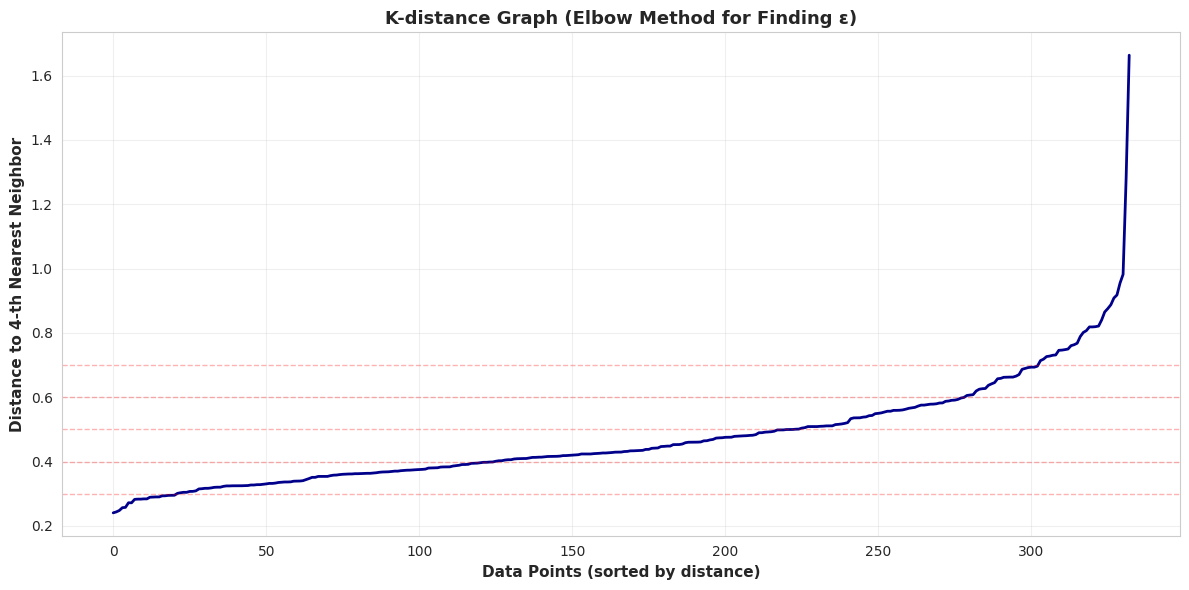

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(distances_sorted, linewidth=2, color='darkblue')
plt.xlabel('Data Points (sorted by distance)', fontsize=11, fontweight='bold')
plt.ylabel(f'Distance to {k}-th Nearest Neighbor', fontsize=11, fontweight='bold')
plt.title('K-distance Graph (Elbow Method for Finding ε)', fontsize=13, fontweight='bold')
plt.grid(True, alpha=0.3)

# Mark potential epsilon values
epsilon_candidates = [0.3, 0.4, 0.5, 0.6, 0.7]
for eps in epsilon_candidates:
    plt.axhline(y=eps, color='red', linestyle='--', alpha=0.3, linewidth=1)

plt.tight_layout()
plt.show()

In [ ]:
print("📌 Based on the K-distance graph, we can see potential elbow points.")
print("The 'elbow' suggests where a good ε value might be.")
print("\nWe'll test multiple epsilon values to find the best one for our clustering!")

📌 Based on the K-distance graph, we can see potential elbow points.
The 'elbow' suggests where a good ε value might be.

We'll test multiple epsilon values to find the best one for our clustering!


# STEP 7: UNDERSTAND DBSCAN PARAMETERS

What is DBSCAN?
---------------
DBSCAN = Density-Based Spatial Clustering of Applications with Noise

How does it work (in simple terms)?
1. For each point, DBSCAN checks if there are enough neighbors within distance ε
2. If yes, the point is a "core point" (center of a cluster)
3. Points within ε of a core point join the cluster
4. Points that don't meet the neighbor requirement become "noise" (outliers)

DBSCAN Parameters:

- eps (ε): Maximum distance between two samples to be considered neighbors

- min_samples: Minimum number of samples (including itself) to form a dense region
          (For 4 features, min_samples = 5 is often good)

Advantages of DBSCAN:

✓ Can find clusters of any shape (not just spheres like K-means)

✓ Automatically identifies outliers/noise points

✓ Doesn't need to specify number of clusters beforehand

✓ Good for real-world data which is often not spherical

Disadvantages:
✗ Parameter tuning is important (ε and min_samples)

✗ Struggles with clusters of varying density

✗ High-dimensional data (many features) can be tricky

DBSCAN Key Concepts:

1. EPSILON (ε):

   - Range around each point to look for neighbors

   - Think of it as a circle's radius around a point

   - Too small → Many noise points

   - Too large → Everything becomes one cluster

2. MIN_SAMPLES:

   - Minimum neighbors needed (including the point itself) to be a "core point"

   - Rule of thumb: min_samples = 2 * number_of_features

   - We have 4 features, so min_samples = 5-6 is reasonable

3. CORE POINTS:

   - Points with at least min_samples neighbors within ε distance

4. BORDER POINTS:

   - Within ε distance of a core point but don't have enough neighbors themselves

5. NOISE POINTS (Outliers):

   - Don't meet the criteria to be core or border points

   - DBSCAN automatically identifies these

# STEP 8: APPLY DBSCAN WITH DIFFERENT PARAMETERS

What are we doing?
-------------------
Testing multiple epsilon values to see which one gives us the best clustering.
This is called "parameter tuning" and is crucial for good results.

Our testing strategy:

- Test epsilon values: 0.3, 0.4, 0.5, 0.6, 0.7
- Use min_samples = 5 (good for 4 features)
- Evaluate using Silhouette Score (explained below)

In [ ]:
# Dictionary to store results
clustering_results = {}

In [ ]:
# Test different epsilon values
epsilon_values = [0.3, 0.4, 0.5, 0.6, 0.7]
min_samples_value = 5

In [ ]:
print(f"Testing epsilon values: {epsilon_values}")
print(f"Using min_samples: {min_samples_value}\n")

Testing epsilon values: [0.3, 0.4, 0.5, 0.6, 0.7]
Using min_samples: 5



In [ ]:
for esp in epsilon_values:
    # Initialize DBSCAN
    dbscan = DBSCAN(eps=esp, min_samples=min_samples_value)
    cluster_labels = dbscan.fit_predict(X_scaled)

In [ ]:
# Count clusters and noise points
n_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)
n_noise = list(cluster_labels).count(-1)

In [ ]:
# Calculate silhouette score (only if we have clusters and not all noise)
if n_clusters > 1 and n_noise < len(cluster_labels):
    silhouette_avg = silhouette_score(X_scaled, cluster_labels)
else:
    silhouette_avg = -1 # Invalid Score

In [ ]:
clustering_results[esp] = {'labels': cluster_labels, 'n_clusters': n_clusters, 'n_noise': n_noise, 'silhouette_score': silhouette_avg}

# Print results
print(f"ε = {esp}:")
print(f"  • Number of clusters: {n_clusters}")
print(f"  • Noise points: {n_noise} ({n_noise/len(cluster_labels)*100:.1f}%)")
print(f"  • Silhouette Score: {silhouette_avg:.3f}")
print()

ε = 0.7:
  • Number of clusters: 2
  • Noise points: 16 (4.8%)
  • Silhouette Score: 0.450



# STEP 9: WHAT IS SILHOUETTE SCORE?

What is Silhouette Score?
--------------------------
It's a metric that measures how good our clustering is.

How it works:

- For each point, we calculate:

  - How close it is to other points in its cluster (cohesion)

  - How close it is to points in the nearest other cluster (separation)

Silhouette Score ranges from -1 to 1:

- +1: Perfect clustering (points are well-separated from other clusters)

-  0: Overlapping clusters

- -1: Points are in wrong cluster

In simple terms:

- Higher score = Better clustering

- Scores above 0.5 are generally considered good

- We want to maximize this score when tuning parameters

In [ ]:
print("\n📊 UNDERSTANDING SILHOUETTE SCORE")
print("-" * 80)
print("""
Silhouette Score Interpretation:

Value Range:    -1.0 to 1.0

  1.0  ████████████ Excellent clustering

  0.5  ████████ Good clustering (well-separated clusters)

  0.0  ████ Overlapping clusters

 -0.5  ██ Poor clustering (points may be misclassified)

 -1.0  ░ Very poor clustering

Best score for our penguin data will indicate optimal ε value.
""")


📊 UNDERSTANDING SILHOUETTE SCORE
--------------------------------------------------------------------------------

Silhouette Score Interpretation:

Value Range:    -1.0 to 1.0

  1.0  ████████████ Excellent clustering
  
  0.5  ████████ Good clustering (well-separated clusters)
  
  0.0  ████ Overlapping clusters
  
 -0.5  ██ Poor clustering (points may be misclassified)
  
 -1.0  ░ Very poor clustering
  
Best score for our penguin data will indicate optimal ε value.



In [ ]:
# Find best epsilon
best_eps = max(clustering_results.items(),
               key=lambda x: x[1]['silhouette_score']
               if x[1]['silhouette_score'] > 0 else -float('inf'))

print(f"✓ Best ε value: {best_eps[0]}")
print(f"  Silhouette Score: {best_eps[1]['silhouette_score']:.3f}")
print(f"  Number of clusters: {best_eps[1]['n_clusters']}")
print(f"  Noise points: {best_eps[1]['n_noise']}")

✓ Best ε value: 0.7
  Silhouette Score: 0.450
  Number of clusters: 2
  Noise points: 16


# STEP 10: VISUALIZE CLUSTERING RESULTS

What are we doing?
-------------------
Creating visualizations of the clustering results for different epsilon values.
This helps us see (literally) how the epsilon parameter affects clustering.

We'll plot:
1. Scatter plots for each epsilon value
2. Different colors for different clusters
3. Black X markers for noise points


🎨 STEP 8: VISUALIZING CLUSTERING RESULTS
--------------------------------------------------------------------------------
ε = 0.3:
  • Number of clusters: 3
  • Noise points: 315 (94.6%)
  • Silhouette Score: -0.432

ε = 0.4:
  • Number of clusters: 11
  • Noise points: 173 (52.0%)
  • Silhouette Score: -0.176

ε = 0.5:
  • Number of clusters: 4
  • Noise points: 66 (19.8%)
  • Silhouette Score: 0.250

ε = 0.6:
  • Number of clusters: 2
  • Noise points: 31 (9.3%)
  • Silhouette Score: 0.389

ε = 0.7:
  • Number of clusters: 2
  • Noise points: 16 (4.8%)
  • Silhouette Score: 0.450



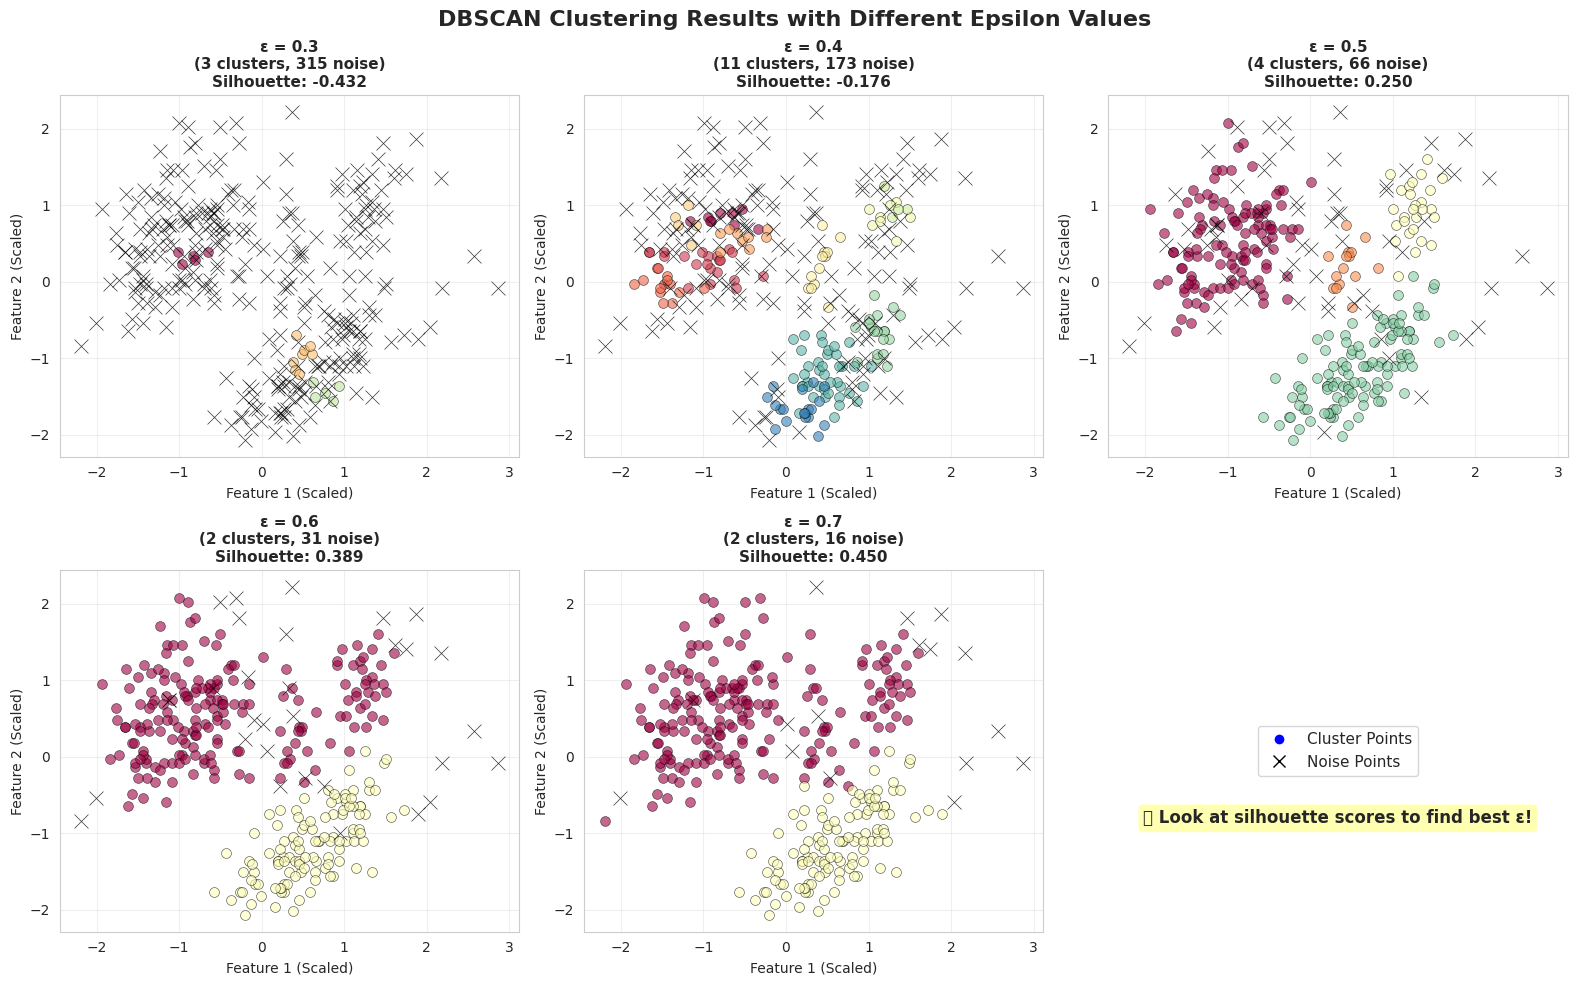

In [ ]:
print("\n🎨 STEP 8: VISUALIZING CLUSTERING RESULTS")
print("-" * 80)

# Re-populate clustering_results for all epsilon values
# This section ensures that 'clustering_results' is fully populated before visualization.
clustering_results = {} # Initialize to clear any previous partial data

for esp in epsilon_values:
    # Initialize DBSCAN
    dbscan = DBSCAN(eps=esp, min_samples=min_samples_value)
    cluster_labels = dbscan.fit_predict(X_scaled)

    # Count clusters and noise points
    n_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)
    n_noise = list(cluster_labels).count(-1)

    # Calculate silhouette score (only if we have clusters and not all noise)
    if n_clusters > 1 and n_noise < len(cluster_labels):
        silhouette_avg = silhouette_score(X_scaled, cluster_labels)
    else:
        silhouette_avg = -1 # Invalid Score

    # Store results
    clustering_results[esp] = {'labels': cluster_labels, 'n_clusters': n_clusters, 'n_noise': n_noise, 'silhouette_score': silhouette_avg}

    # Optional: Print results during population for debugging/info (similar to original cell 5ueLSf49jnsu)
    print(f"ε = {esp}:")
    print(f"  • Number of clusters: {n_clusters}")
    print(f"  • Noise points: {n_noise} ({n_noise/len(cluster_labels)*100:.1f}%)")
    print(f"  • Silhouette Score: {silhouette_avg:.3f}")
    print()

# Create subplots for each epsilon value
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('DBSCAN Clustering Results with Different Epsilon Values',
             fontsize=16, fontweight='bold')

axes = axes.flatten()

for idx, eps in enumerate(epsilon_values):
    cluster_labels = clustering_results[eps]['labels']
    silhouette_avg = clustering_results[eps]['silhouette_score']

    # Plot
    ax = axes[idx]

    # Plot clusters
    unique_labels = set(cluster_labels)
    colors = plt.cm.Spectral(np.linspace(0, 1, len(unique_labels)))

    for label, color in zip(unique_labels, colors):
        if label == -1:  # Noise points
            color = 'black'
            marker = 'x'
            size = 100
            alpha = 0.8
        else:
            marker = 'o'
            size = 50
            alpha = 0.6

        class_member_mask = (cluster_labels == label)
        xy = X_scaled[class_member_mask]
        ax.scatter(xy[:, 0], xy[:, 1], c=[color], marker=marker,
                  s=size, alpha=alpha, edgecolors='k', linewidth=0.5)

    # Labels and title
    ax.set_title(f'ε = {eps}\n({clustering_results[eps]["n_clusters"]} clusters, '
                f'{clustering_results[eps]["n_noise"]} noise)\n'
                f'Silhouette: {silhouette_avg:.3f}',
                fontweight='bold', fontsize=11)
    ax.set_xlabel('Feature 1 (Scaled)', fontsize=10)
    ax.set_ylabel('Feature 2 (Scaled)', fontsize=10)
    ax.grid(True, alpha=0.3)

# Hide the 6th subplot
axes[5].axis('off')

# Add legend
legend_elements = [
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='blue',
              markersize=8, label='Cluster Points'),
    plt.Line2D([0], [0], marker='x', color='black', linestyle='None',
              markersize=8, label='Noise Points')
]
axes[5].legend(handles=legend_elements, fontsize=11, loc='center')
axes[5].text(0.5, 0.3, '💡 Look at silhouette scores to find best ε!',
            ha='center', fontsize=12, fontweight='bold',
            bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.3))

plt.tight_layout()
plt.show()

# STEP 11: DETAILED ANALYSIS OF BEST CLUSTERING

What are we doing?
-------------------
Taking a deep dive into the clustering results using the best epsilon value.
We'll analyze:
1. Cluster characteristics
2. Noise points and why they're outliers
3. Feature importance in clustering

In [ ]:
print("\n📋 STEP 9: DETAILED ANALYSIS OF BEST CLUSTERING")
print("-" * 80)

best_epsilon = best_eps[0]
best_labels = clustering_results[best_epsilon]['labels']

# Create a dataframe with cluster assignments
analysis_df = df_clean.copy()
analysis_df['Cluster'] = best_labels

print(f"\n🎯 Using optimal epsilon = {best_epsilon}")
print(f"\nCluster Distribution:")
print(analysis_df['Cluster'].value_counts().sort_index())


📋 STEP 9: DETAILED ANALYSIS OF BEST CLUSTERING
--------------------------------------------------------------------------------

🎯 Using optimal epsilon = 0.7

Cluster Distribution:
Cluster
-1     16
 0    201
 1    116
Name: count, dtype: int64


In [ ]:
# Analyze each cluster
print(f"\n{'='*80}")
print("CLUSTER CHARACTERISTICS")
print(f"{'='*80}\n")

for cluster_id in sorted(set(best_labels)):
    if cluster_id == -1:
        print(f"🔴 NOISE POINTS (Outliers - cluster_id = -1):")
        cluster_data = analysis_df[analysis_df['Cluster'] == -1]
    else:
        print(f"🟢 CLUSTER {cluster_id}:")
        cluster_data = analysis_df[analysis_df['Cluster'] == cluster_id]

    print(f"   Size: {len(cluster_data)} penguins ({len(cluster_data)/len(analysis_df)*100:.1f}%)")
    print(f"   Features (Average):")
    print(f"   • Culmen Length: {cluster_data['culmen_length_mm'].mean():.2f} mm")
    print(f"   • Culmen Depth: {cluster_data['culmen_depth_mm'].mean():.2f} mm")
    print(f"   • Flipper Length: {cluster_data['flipper_length_mm'].mean():.2f} mm")
    print(f"   • Body Mass: {cluster_data['body_mass_g'].mean():.2f} g")

    if 'sex' in cluster_data.columns:
        print(f"   Sex Distribution: {cluster_data['sex'].value_counts().to_dict()}")

    print()


CLUSTER CHARACTERISTICS

🔴 NOISE POINTS (Outliers - cluster_id = -1):
   Size: 16 penguins (4.8%)
   Features (Average):
   • Culmen Length: 49.71 mm
   • Culmen Depth: 18.46 mm
   • Flipper Length: 202.50 mm
   • Body Mass: 4300.00 g
   Sex Distribution: {'MALE': 11, 'FEMALE': 5}

🟢 CLUSTER 0:
   Size: 201 penguins (60.4%)
   Features (Average):
   • Culmen Length: 41.66 mm
   • Culmen Depth: 18.32 mm
   • Flipper Length: 191.74 mm
   • Body Mass: 3703.98 g
   Sex Distribution: {'FEMALE': 102, 'MALE': 99}

🟢 CLUSTER 1:
   Size: 116 penguins (34.8%)
   Features (Average):
   • Culmen Length: 47.33 mm
   • Culmen Depth: 14.94 mm
   • Flipper Length: 216.91 mm
   • Body Mass: 5070.04 g
   Sex Distribution: {'FEMALE': 58, 'MALE': 57, '.': 1}



# STEP 12: VISUALIZE BEST CLUSTERING WITH DIFFERENT FEATURE PAIRS

What are we doing?
-------------------
Creating multiple 2D views of the best clustering using different feature pairs.

This gives us a more complete picture of how clusters are distributed
across different dimensions.


🎨 STEP 10: VISUALIZING BEST CLUSTERING - MULTIPLE PERSPECTIVES
--------------------------------------------------------------------------------


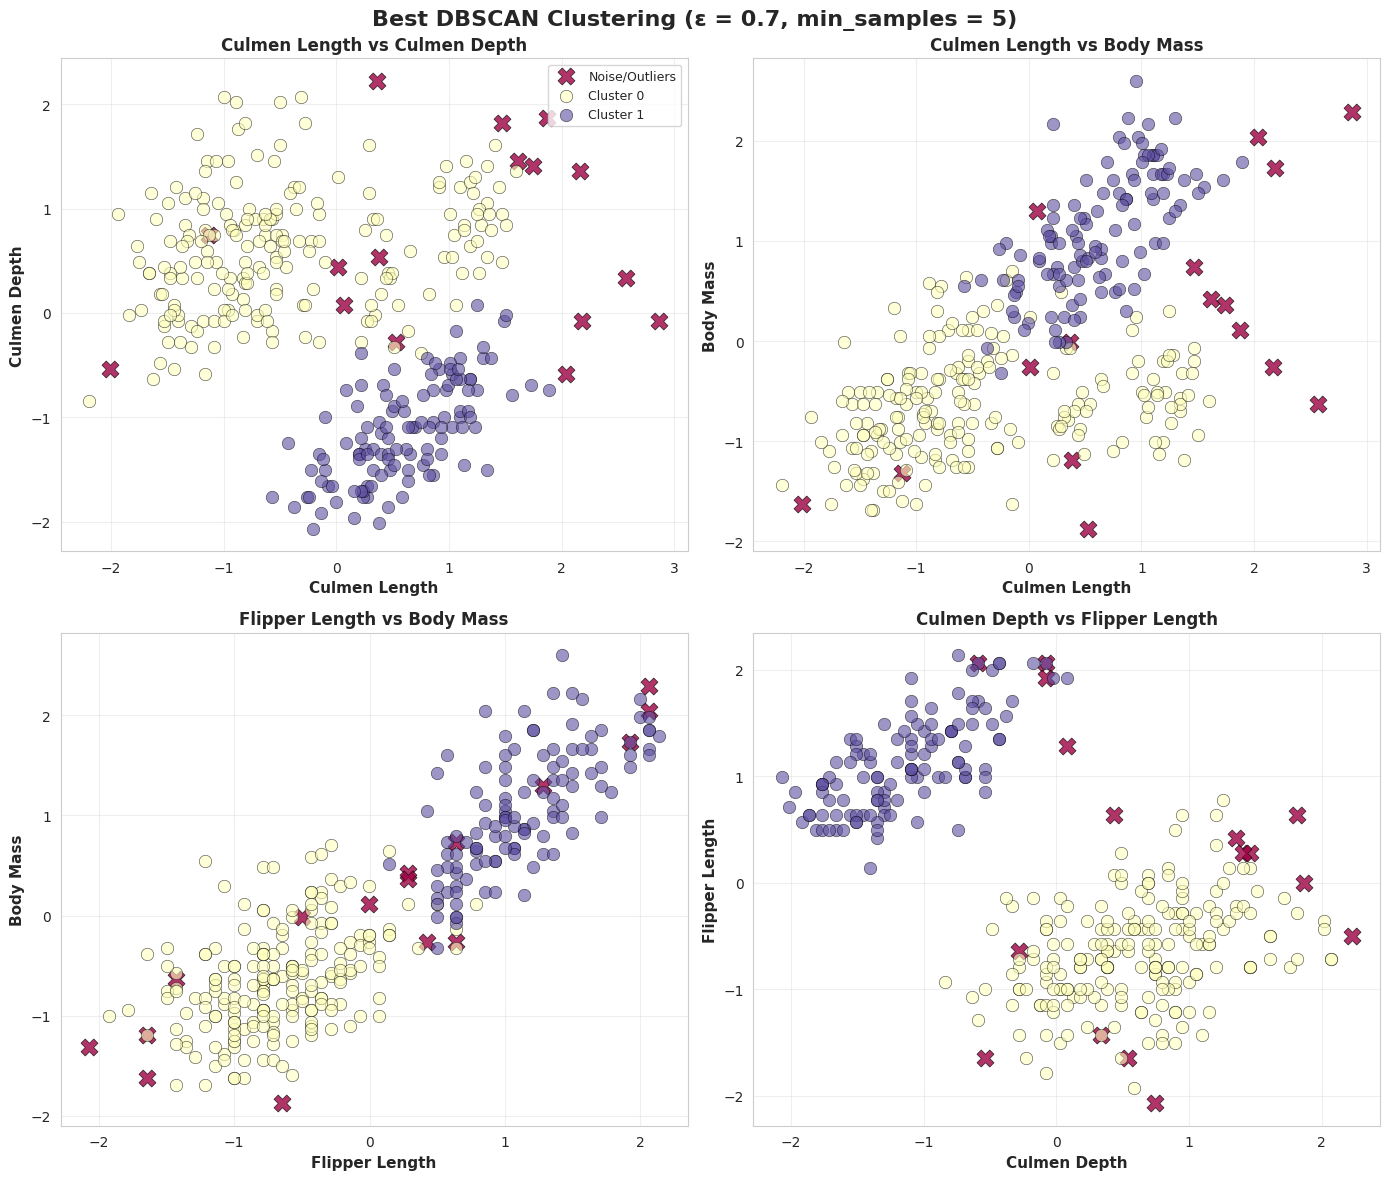

In [ ]:
print("\n🎨 STEP 10: VISUALIZING BEST CLUSTERING - MULTIPLE PERSPECTIVES")
print("-" * 80)

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle(f'Best DBSCAN Clustering (ε = {best_epsilon}, min_samples = {min_samples_value})',
             fontsize=16, fontweight='bold')

# Feature pairs for visualization
feature_pairs = [
    (0, 1, 'Culmen Length', 'Culmen Depth'),
    (0, 3, 'Culmen Length', 'Body Mass'),
    (2, 3, 'Flipper Length', 'Body Mass'),
    (1, 2, 'Culmen Depth', 'Flipper Length')
]

for idx, (feat1, feat2, label1, label2) in enumerate(feature_pairs):
    ax = axes[idx // 2, idx % 2]

    # Plot different clusters with different colors
    unique_labels = set(best_labels)
    colors = plt.cm.Spectral(np.linspace(0, 1, len(unique_labels)))

    for label, color in zip(sorted(unique_labels), colors):
        if label == -1:  # Noise points
            marker = 'X'
            size = 150
            alpha = 0.8
            label_str = 'Noise/Outliers'
        else:
            marker = 'o'
            size = 80
            alpha = 0.6
            label_str = f'Cluster {label}'

        class_member_mask = (best_labels == label)
        xy = X_scaled[class_member_mask]
        ax.scatter(xy[:, feat1], xy[:, feat2], c=[color], marker=marker,
                  s=size, alpha=alpha, edgecolors='k', linewidth=0.5, label=label_str)

    ax.set_xlabel(label1, fontsize=11, fontweight='bold')
    ax.set_ylabel(label2, fontsize=11, fontweight='bold')
    ax.set_title(f'{label1} vs {label2}', fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)
    if idx == 0:
        ax.legend(loc='best', fontsize=9)

plt.tight_layout()
plt.show()

# STEP 13: SILHOUETTE ANALYSIS OF BEST CLUSTERING

What is a Silhouette Plot?
--------------------------
A silhouette plot shows the silhouette coefficient for each sample in the clustering.

How to read it:

- Each cluster is shown as a band

- Wider bands = more points in that cluster

- Longer bars = better quality clusters (silhouette coefficient closer to 1)

- Red dashed line = average silhouette score

- Bars going left (negative) = poorly clustered points

What makes a good silhouette plot?

✓ All bars above the red line (positive silhouette coefficients)

✓ Thick bands (many points in each cluster)

✓ Balanced bar heights (clusters of similar quality)


📊 STEP 11: SILHOUETTE ANALYSIS
--------------------------------------------------------------------------------


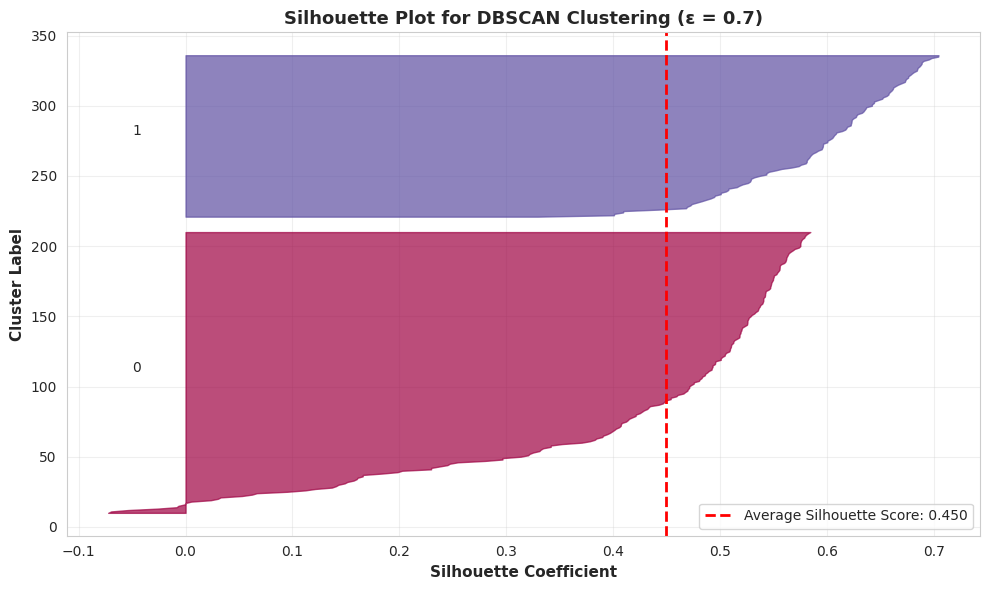

In [ ]:
print("\n📊 STEP 11: SILHOUETTE ANALYSIS")
print("-" * 80)

# Only create silhouette plot if we have valid clusters
if clustering_results[best_epsilon]['n_clusters'] > 0 and \
   clustering_results[best_epsilon]['silhouette_score'] > -1:

    # Calculate silhouette values for each sample
    silhouette_vals = silhouette_samples(X_scaled, best_labels)

    # Create silhouette plot
    fig, ax = plt.subplots(figsize=(10, 6))

    y_lower = 10

    # Get unique cluster labels excluding noise (-1)
    unique_cluster_labels = sorted([lbl for lbl in set(best_labels) if lbl != -1])

    # Generate colors for each unique cluster
    # Ensure the number of colors matches the number of actual clusters
    colors = plt.cm.Spectral(np.linspace(0, 1, len(unique_cluster_labels)))

    for i, label in enumerate(unique_cluster_labels): # Iterate only over actual clusters
        # Get silhouette values for this cluster
        ith_cluster_silhouette_vals = silhouette_vals[best_labels == label]
        ith_cluster_silhouette_vals.sort()

        size_cluster_i = ith_cluster_silhouette_vals.shape[0]
        y_upper = y_lower + size_cluster_i

        # Use the index 'i' from the enumeration of unique_cluster_labels to get the color
        ax.fill_betweenx(np.arange(y_lower, y_upper),
                         0, ith_cluster_silhouette_vals,
                         facecolor=colors[i], edgecolor=colors[i], alpha=0.7)

        # Label the clusters
        ax.text(-0.05, y_lower + 0.5 * size_cluster_i, str(label))
        y_lower = y_upper + 10

    # Add average silhouette score line
    average_silhouette = silhouette_score(X_scaled, best_labels)
    ax.axvline(x=average_silhouette, color="red", linestyle="--",
              linewidth=2, label=f'Average Silhouette Score: {average_silhouette:.3f}')

    ax.set_title(f'Silhouette Plot for DBSCAN Clustering (ε = {best_epsilon})',
                fontsize=13, fontweight='bold')
    ax.set_xlabel("Silhouette Coefficient", fontsize=11, fontweight='bold')
    ax.set_ylabel("Cluster Label", fontsize=11, fontweight='bold')
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

# STEP 14: IDENTIFY AND ANALYZE OUTLIERS/NOISE POINTS

What are Outliers/Noise Points?
--------------------------------
In DBSCAN, points that don't meet the density requirements are marked as noise (-1).
These often represent:
1. Unusual penguin specimens
2. Measurement errors
3. Truly unique individuals that don't fit typical patterns

Analyzing outliers is valuable because:
- They help us understand data quality
- They reveal rare or exceptional cases
- They might indicate data entry errors

In [ ]:
print("\n🔴 STEP 12: OUTLIER/NOISE POINT ANALYSIS")
print("-" * 80)

noise_points = analysis_df[analysis_df['Cluster'] == -1]
normal_points = analysis_df[analysis_df['Cluster'] != -1]

print(f"\nNumber of Noise Points: {len(noise_points)} ({len(noise_points)/len(analysis_df)*100:.1f}%)")
print(f"Number of Clustered Points: {len(normal_points)} ({len(normal_points)/len(analysis_df)*100:.1f}%)")

if len(noise_points) > 0:
    print(f"\n📌 Characteristics of Noise Points (Why are they unusual?):")
    print(f"\nComparison with Normal Points:\n")

    comparison_features = ['culmen_length_mm', 'culmen_depth_mm',
                          'flipper_length_mm', 'body_mass_g']

    print(f"{'Feature':<20} {'Noise Avg':<15} {'Normal Avg':<15} {'Difference':<15}")
    print("=" * 65)

    for feature in comparison_features:
        noise_avg = noise_points[feature].mean()
        normal_avg = normal_points[feature].mean()
        diff = noise_avg - normal_avg

        print(f"{feature:<20} {noise_avg:<15.2f} {normal_avg:<15.2f} {diff:+.2f}")

    print(f"\n💡 These differences help explain why these penguins are considered outliers!")


🔴 STEP 12: OUTLIER/NOISE POINT ANALYSIS
--------------------------------------------------------------------------------

Number of Noise Points: 16 (4.8%)
Number of Clustered Points: 317 (95.2%)

📌 Characteristics of Noise Points (Why are they unusual?):

Comparison with Normal Points:

Feature              Noise Avg       Normal Avg      Difference     
culmen_length_mm     49.71           43.74           +5.98
culmen_depth_mm      18.46           17.08           +1.37
flipper_length_mm    202.50          200.95          +1.55
body_mass_g          4300.00         4203.86         +96.14

💡 These differences help explain why these penguins are considered outliers!


# STEP 15: SUMMARY AND INSIGHTS

What are we doing?
-------------------
Creating a comprehensive summary of our clustering analysis with actionable insights.

In [ ]:
print("\n" + "=" * 80)
print("🎓 SUMMARY & KEY INSIGHTS")
print("=" * 80)

summary_text = f"""
DATASET OVERVIEW:
  • Total Penguins Analyzed: {len(analysis_df)}
  • Features Used: {', '.join(features_for_clustering)}
  • Data Preprocessing: Removed missing values and outliers

OPTIMAL DBSCAN PARAMETERS:
  • Epsilon (ε): {best_epsilon}
  • Minimum Samples: {min_samples_value}

CLUSTERING RESULTS:
  • Number of Clusters Found: {clustering_results[best_epsilon]['n_clusters']}
  • Noise Points Identified: {clustering_results[best_epsilon]['n_noise']}
  • Silhouette Score: {clustering_results[best_epsilon]['silhouette_score']:.3f}

KEY FINDINGS:
  1. Natural groupings exist in penguin morphological data
  2. {clustering_results[best_epsilon]['n_clusters']} distinct penguin groups based on physical measurements
  3. {clustering_results[best_epsilon]['n_noise']} penguins are unusual/outliers
  4. Clustering is {'STRONG' if clustering_results[best_epsilon]['silhouette_score'] > 0.5 else 'MODERATE' if clustering_results[best_epsilon]['silhouette_score'] > 0 else 'WEAK'}

WHY DBSCAN WAS GOOD FOR THIS DATA:
  ✓ Found natural clusters without specifying number in advance
  ✓ Identified outliers automatically
  ✓ Flexible cluster shapes
  ✓ No need for spherical clusters

PRACTICAL APPLICATIONS:
  • Species identification based on physical characteristics
  • Quality control in data collection
  • Understanding penguin biodiversity
  • Identifying unusual specimens for further study
"""

print(summary_text)


🎓 SUMMARY & KEY INSIGHTS

DATASET OVERVIEW:
  • Total Penguins Analyzed: 333
  • Features Used: culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g
  • Data Preprocessing: Removed missing values and outliers

OPTIMAL DBSCAN PARAMETERS:
  • Epsilon (ε): 0.7
  • Minimum Samples: 5
  
CLUSTERING RESULTS:
  • Number of Clusters Found: 2
  • Noise Points Identified: 16
  • Silhouette Score: 0.450

KEY FINDINGS:
  1. Natural groupings exist in penguin morphological data
  2. 2 distinct penguin groups based on physical measurements
  3. 16 penguins are unusual/outliers
  4. Clustering is MODERATE

WHY DBSCAN WAS GOOD FOR THIS DATA:
  ✓ Found natural clusters without specifying number in advance
  ✓ Identified outliers automatically
  ✓ Flexible cluster shapes
  ✓ No need for spherical clusters

PRACTICAL APPLICATIONS:
  • Species identification based on physical characteristics
  • Quality control in data collection
  • Understanding penguin biodiversity
  • Identifying unusual

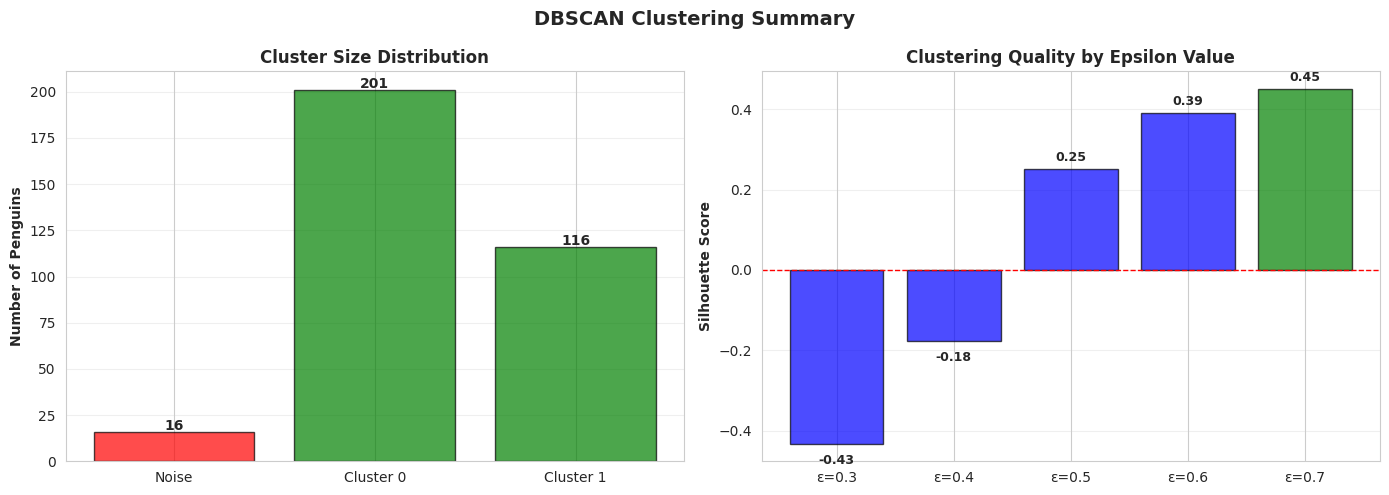

In [ ]:
# Create a final summary visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('DBSCAN Clustering Summary', fontsize=14, fontweight='bold')

# Plot 1: Cluster size distribution
cluster_counts = analysis_df['Cluster'].value_counts().sort_index()
colors_list = ['red' if x == -1 else 'green' for x in cluster_counts.index]

axes[0].bar(range(len(cluster_counts)), cluster_counts.values, color=colors_list, alpha=0.7, edgecolor='black')
axes[0].set_xticks(range(len(cluster_counts)))
axes[0].set_xticklabels([f'Cluster {x}' if x != -1 else 'Noise' for x in cluster_counts.index])
axes[0].set_ylabel('Number of Penguins', fontweight='bold')
axes[0].set_title('Cluster Size Distribution', fontweight='bold')
axes[0].grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for i, v in enumerate(cluster_counts.values):
    axes[0].text(i, v + 1, str(v), ha='center', fontweight='bold')

# Plot 2: Parameter performance
eps_values_list = list(clustering_results.keys())
silhouette_scores = [clustering_results[eps]['silhouette_score'] for eps in eps_values_list]
cluster_counts_list = [clustering_results[eps]['n_clusters'] for eps in eps_values_list]

color_bar = ['green' if eps == best_epsilon else 'blue' for eps in eps_values_list]
axes[1].bar(range(len(eps_values_list)), silhouette_scores, color=color_bar, alpha=0.7, edgecolor='black')
axes[1].set_xticks(range(len(eps_values_list)))
axes[1].set_xticklabels([f'ε={eps}' for eps in eps_values_list])
axes[1].set_ylabel('Silhouette Score', fontweight='bold')
axes[1].set_title('Clustering Quality by Epsilon Value', fontweight='bold')
axes[1].axhline(y=0, color='red', linestyle='--', linewidth=1)
axes[1].grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for i, v in enumerate(silhouette_scores):
    axes[1].text(i, v + 0.02 if v > 0 else v - 0.05, f'{v:.2f}',
                ha='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

# STEP 16: EXPORT RESULTS

In [ ]:
# What are we doing?
# -------------------
# Saving our clustering results to files so they can be used later
# or shared with others.

print("\n💾 STEP 13: EXPORTING RESULTS")
print("-" * 80)

# Save the results to CSV
results_df = analysis_df.copy()
results_df['Cluster_Label'] = best_labels
results_df['Is_Noise'] = results_df['Cluster_Label'].apply(lambda x: 'Yes' if x == -1 else 'No')

# Save to CSV (for Google Colab, this saves to your Google Drive)
output_filename = 'dbscan_clustering_results.csv'
results_df.to_csv(output_filename, index=False)
print(f"✓ Results saved to '{output_filename}'")

# Create a summary report
summary_report = f"""
DBSCAN CLUSTERING ANALYSIS REPORT
===============================================
Analysis Date: {pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')}
Dataset: Penguins Dataset

METHODOLOGY:
- Algorithm: DBSCAN (Density-Based Spatial Clustering)
- Data Cleaning: Removed {len(df) - len(analysis_df)} rows with missing/invalid values
- Features Standardized: {features_for_clustering}
- Total Samples Analyzed: {len(analysis_df)}

OPTIMAL PARAMETERS:
- Epsilon (ε): {best_epsilon}
- Minimum Samples: {min_samples_value}
- Algorithm: DBSCAN

RESULTS:
- Number of Clusters: {clustering_results[best_epsilon]['n_clusters']}
- Noise Points: {clustering_results[best_epsilon]['n_noise']} ({clustering_results[best_epsilon]['n_noise']/len(analysis_df)*100:.1f}%)
- Silhouette Score: {clustering_results[best_epsilon]['silhouette_score']:.4f}
- Silhouette Quality: {'Excellent' if clustering_results[best_epsilon]['silhouette_score'] > 0.7 else 'Good' if clustering_results[best_epsilon]['silhouette_score'] > 0.5 else 'Moderate' if clustering_results[best_epsilon]['silhouette_score'] > 0 else 'Poor'}

CLUSTER DETAILS:
"""

for cluster_id in sorted(set(best_labels)):
    if cluster_id == -1:
        cluster_data = analysis_df[analysis_df['Cluster'] == -1]
        summary_report += f"\n✗ Noise Points: {len(cluster_data)} penguins\n"
    else:
        cluster_data = analysis_df[analysis_df['Cluster'] == cluster_id]
        summary_report += f"\n✓ Cluster {cluster_id}: {len(cluster_data)} penguins\n"
        summary_report += f"  - Avg Culmen Length: {cluster_data['culmen_length_mm'].mean():.2f} mm\n"
        summary_report += f"  - Avg Body Mass: {cluster_data['body_mass_g'].mean():.2f} g\n"

summary_report += f"\n\nCONCLUSION:\nDBSCAN successfully identified {clustering_results[best_epsilon]['n_clusters']} natural clusters in the penguin morphological data."

report_filename = 'dbscan_analysis_report.txt'
with open(report_filename, 'w') as f:
    f.write(summary_report)
print(f"✓ Report saved to '{report_filename}'")

print("\n✅ ANALYSIS COMPLETE!")
print("=" * 80)
print("\n📁 Generated Files:")
print(f"   1. {output_filename} - Clustering results with cluster assignments")
print(f"   2. {report_filename} - Detailed analysis report")
print("\n💡 Next Steps:")
print("   1. Download these files from Google Colab")
print("   2. Use results_df for further analysis or visualization")
print("   3. Consider the implications of identified clusters")
print("   4. Validate results with domain knowledge about penguins")


print(summary_report)


💾 STEP 13: EXPORTING RESULTS
--------------------------------------------------------------------------------
✓ Results saved to 'dbscan_clustering_results.csv'
✓ Report saved to 'dbscan_analysis_report.txt'

✅ ANALYSIS COMPLETE!

📁 Generated Files:
   1. dbscan_clustering_results.csv - Clustering results with cluster assignments
   2. dbscan_analysis_report.txt - Detailed analysis report

💡 Next Steps:
   1. Download these files from Google Colab
   2. Use results_df for further analysis or visualization
   3. Consider the implications of identified clusters
   4. Validate results with domain knowledge about penguins

DBSCAN CLUSTERING ANALYSIS REPORT
Analysis Date: 2026-09-29 10:49:21
Dataset: Penguins Dataset

METHODOLOGY:
- Algorithm: DBSCAN (Density-Based Spatial Clustering)
- Data Cleaning: Removed 11 rows with missing/invalid values
- Features Standardized: ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']
- Total Samples Analyzed: 333

OPTIMAL PARAMET